# 02 · Baselines and the backtest: how good is "no model"?

Before any model, the yardstick. A forecast is only worth building if it beats rules a planner
could apply in a spreadsheet. Four such rules, all applied to every node (nation, states, metros,
counties) at once:

| Rule | Forecast | Plain words |
|---|---|---|
| **naive** | no change | "values stay where they are" |
| **drift** | average monthly growth since 2008 continues | "the long average holds" |
| **momentum** | last 12 months' average monthly growth continues | "the recent trend holds" |
| **long_run** | median monthly growth of the last 4 years continues | Zillow's long-run anchor |

**How they are scored.** A rolling-origin backtest: stand at every month-end from January 2012,
use only data up to that month, forecast 1, 3, 6 and 12 months ahead, and compare with what
happened. Think of it as replaying 14 years of forecast meetings and keeping score. The error is
in cumulative growth, in percentage points (pp): a forecast of +3% against an outcome of +5% is
an error of 2 pp, whatever the price level.

| | |
|---|---|
| **Question** | How accurate are simple rules, at each level and horizon, and where do they break? |
| **Answer** | Momentum (the last 12 months' growth continues) is the best simple rule. For metros, its 12-month error is 5.9 pp RMSE against 7.6 pp for "no change", and it gets the direction right 84% of the time. It fails at turning points: in the 2022-23 rate shock, its metro 12-month error was 10.7 pp, worse than "no change" (8.1 pp). Over Zillow's own test window it scores below Zillow's published error (1 month: 0.0056 vs 0.0105), but that mostly reflects forecasting a smoothed series. The bar for notebook 03: beat momentum, above all at turning points. |
| **Next** | Notebook 03 fits statistical, panel and Zillow-style models and reconciles them. |

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from housing import backtest as bt
from housing import panel
from housing.config import HORIZONS, use_synthetic
from housing.plots import COLORS, save, style, write_metrics

style()
if use_synthetic():
    print("SYNTHETIC DATA: numbers below are made up (CI run).")
Y, S, tags, nodes = panel.load_hierarchy()
L = bt.log_wide(Y)
res = bt.add_context(bt.run(L, bt.BASELINES), bt.mase_scale(L))
print(f"{res['origin'].nunique()} origins ({res['origin'].min():%b %Y} to {res['origin'].max():%b %Y}), "
      f"{L.shape[1]:,} nodes, horizons {HORIZONS}: {len(res):,} forecasts")

165 origins (Jan 2012 to Sep 2025), 2,026 nodes, horizons (1, 3, 6, 12): 5,348,640 forecasts


## 1. Leaderboard by level and horizon

* **RMSE (pp)**: typical size of the growth error, large misses weighted more.
* **Bias (pp)**: average error; negative means the rule predicted less growth than happened.
* **MASE**: error divided by what "no change" would have scored in 2008-11. Below 1 = better than
  that historical naive error. The 2008-11 period was mild month to month, so even naive scores
  above 1 here; read MASE across methods, not against 1.
* **Direction hit**: share of forecasts that got the sign of growth right.

In [2]:
scores = bt.score(res)
scores = bt.skill_vs(scores, "naive")
write_metrics("02_leaderboard", scores)
order = ["National", "State", "Metro", "County"]
board = scores.pivot_table(index=["level", "method"], columns="h", values="rmse_pp", observed=True)
board = board.reindex(order, level=0)
board.round(2)

h                    1     3     6     12
level    method                          
National drift     0.69  2.06  4.01  7.61
         long_run  0.57  1.71  3.28  6.14
         momentum  0.45  1.40  2.78  5.49
         naive     0.68  2.01  3.85  7.17
State    drift     0.71  2.08  4.00  7.51
         long_run  0.61  1.79  3.40  6.27
         momentum  0.48  1.48  2.89  5.66
         naive     0.71  2.09  3.96  7.34
Metro    drift     0.75  2.18  4.11  7.62
         long_run  0.66  1.91  3.54  6.45
         momentum  0.55  1.65  3.13  5.92
         naive     0.77  2.22  4.15  7.62
County   drift     0.77  2.22  4.13  7.57
         long_run  0.69  1.97  3.63  6.53
         momentum  0.59  1.75  3.27  6.11
         naive     0.79  2.27  4.21  7.66

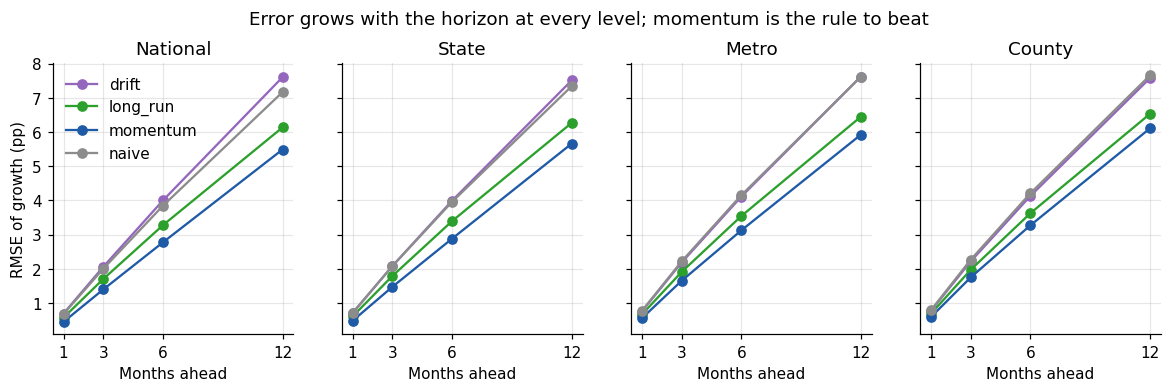

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
colors = {"naive": COLORS["grey"], "drift": "#9467bd", "momentum": COLORS["ours"], "long_run": "#2ca02c"}
for ax, level in zip(axes, order):
    d = scores[scores["level"] == level]
    for m, g in d.groupby("method", observed=True):
        ax.plot(g["h"], g["rmse_pp"], marker="o", label=m, color=colors[m])
    ax.set_title(level)
    ax.set_xlabel("Months ahead")
    ax.set_xticks(list(HORIZONS))
axes[0].set_ylabel("RMSE of growth (pp)")
axes[0].legend(frameon=False)
fig.suptitle("Error grows with the horizon at every level; momentum is the rule to beat", y=1.03)
save(fig, "02_rmse_by_horizon")

## 2. Where the rules break: errors by period

The same scores, split by the month being forecast. Momentum is strong while the market keeps
going the same way and late at turning points: in the 2022 rate shock it kept predicting
pandemic-era growth after prices had stalled.

In [4]:
reg = bt.score(res[res["level"] == "Metro"], by=("method", "regime", "h"))
write_metrics("02_metro_by_regime", reg)
reg.pivot_table(index="regime", columns=["h", "method"], values="rmse_pp", observed=True)[[3, 12]].round(2)

h                   3                              12                         
method           drift long_run momentum naive  drift long_run momentum  naive
regime                                                                        
Recovery 2012-20  1.97     1.59     1.26  1.74   7.40     5.76     4.42   6.06
Pandemic boom     3.48     2.73     2.16  4.01  11.71     8.55     7.36  13.44
Rate shock        1.92     2.40     2.80  1.96   6.81     7.19    10.69   8.14
Flat 2024+        1.28     1.63     1.21  1.34   3.70     5.89     4.38   4.25

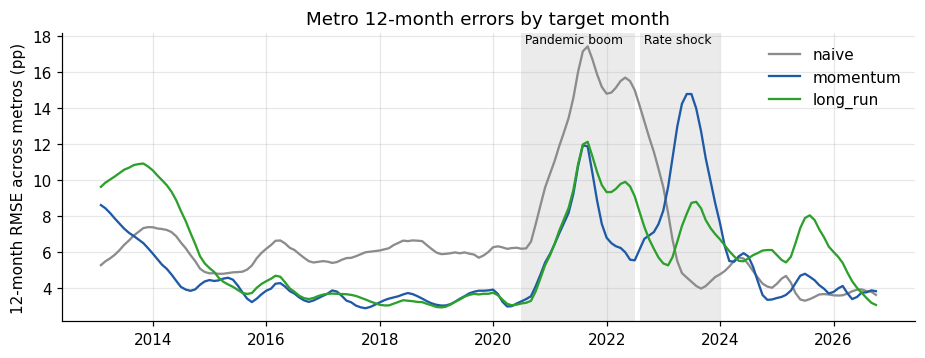

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.4))
m12 = res[(res["level"] == "Metro") & (res["h"] == 12)]
for m in ["naive", "momentum", "long_run"]:
    s = m12[m12["method"] == m].groupby("target")["err"].apply(lambda e: 100 * np.sqrt(np.mean(e ** 2)))
    ax.plot(s.index, s, label=m, color=colors[m])
for a, b, label in bt.REGIMES[1:3]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=COLORS["light"], alpha=0.5, lw=0)
    ax.text(pd.Timestamp(a), 1.0, f" {label}", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
ax.set_ylabel("12-month RMSE across metros (pp)")
ax.set_title("Metro 12-month errors by target month")
ax.legend(frameon=False)
save(fig, "02_metro_error_over_time")

## 3. One metro, many forecast meetings

Every 6 months, the 12-month momentum path drawn from that origin, against the actual series.
The fan shows the turning-point problem directly.

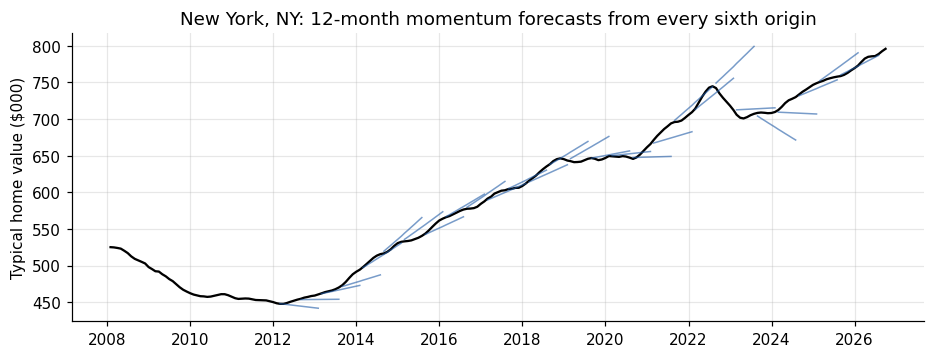

In [6]:
big = Y[Y["unique_id"].str.startswith("MSA:") & ~Y["unique_id"].str.contains("Non-metro")]
example = big.drop_duplicates("unique_id").nlargest(1, "hu")["unique_id"].item()
s = Y[Y["unique_id"] == example].set_index("ds")["typical_value"]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(s.index, s / 1e3, color="k", lw=1.5, label="Actual")
for o in bt.origins(L)[::6]:
    i = L.index.get_loc(o)
    hist = L[[example]].to_numpy()[: i + 1]
    path = [np.exp(bt.momentum(hist, h)[0] - hist[-1, 0]) * s.loc[o] for h in range(1, 13)]
    ax.plot(pd.date_range(o, periods=13, freq="ME")[1:], np.array(path) / 1e3, color=COLORS["ours"], alpha=0.6, lw=1)
ax.set_ylabel("Typical home value ($000)")
ax.set_title(f"{example[4:]}: 12-month momentum forecasts from every sixth origin")
save(fig, "02_example_fan")

## 4. Against Zillow's published accuracy

Zillow reports the accuracy of its own metro forecast for the top 100 metros, forecasts made
from January 2019 to November 2021: RMSE of growth 0.0105 at 1 month, 0.0213 at 3, 0.0388 at 6.
Below, the same statistic for the baselines on the 100 largest metros here, same origins.

**Not like for like, so read with care.** Zillow scores against a *debiased, unsmoothed* ZHVI;
this project forecasts the *smoothed* series, which is easier to forecast one month out because
smoothing carries last month's growth into this month's. The comparison is a sanity check on
scale, not a contest.

In [7]:
zc = bt.zillow_comparison(res, Y)
write_metrics("02_zillow_comparison", zc.reset_index())
zc.round(4)

h,1,3,6
method,,,
drift,0.0088,0.0268,0.0554
long_run,0.0070,0.0210,0.0425
momentum,0.0056,0.0171,0.0332
naive,0.0102,0.0310,0.0642
Zillow (published),0.0105,0.0213,0.0388


## 5. Summary for the next notebook

The number each model in notebook 03 has to beat is momentum's error, level by level:

In [8]:
target = scores[scores["method"] == "momentum"].pivot_table(index="level", columns="h", values="rmse_pp",
                                                             observed=True).reindex(order)
write_metrics("02_bar_to_beat", target.reset_index())
target.round(2)

h,1,3,6,12
level,,,,
National,0.45,1.40,2.78,5.49
State,0.48,1.48,2.89,5.66
Metro,0.55,1.65,3.13,5.92
County,0.59,1.75,3.27,6.11
